# Qwen3.5-27B Post-LoRA Blind Causal Validation

[实验设置与运行说明](../../../docs/experiment_notes/07_appendix_lora_training/06693d721a86e273.md)


In [1]:
# Run once. Every later code cell reports progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 19 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 19 tracked cells.


## 1. Freeze the protocol before opening the blind set

The notebook verifies the previous adapter and discovery artifacts, locks L42 and L50, defines the two new visual styles, and freezes all intervention windows and doses before any new model output is produced.


In [2]:
%%cell_progress 1/19 Mount Drive and select a complete VisualTorque project
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Auditing candidate project roots')
from pathlib import Path
import shutil

PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
REQUIRED_TOOLKIT_PATHS = (
    'pyproject.toml',
    'src/visual_torque_toolkit/__init__.py',
    'src/visual_torque_toolkit/contracts.py',
    'src/visual_torque_toolkit/classify.py',
    'src/visual_torque_toolkit/dataset.py',
    'src/visual_torque_toolkit/edits.py',
    'src/visual_torque_toolkit/generate.py',
    'src/visual_torque_toolkit/prompts.py',
    'src/visual_torque_toolkit/render.py',
    'src/visual_torque_toolkit/splits.py',
    'src/visual_torque_toolkit/world.py',
    'src/visual_torque_toolkit/behavior/__init__.py',
    'src/visual_torque_toolkit/behavior/adapter.py',
    'src/visual_torque_toolkit/behavior/data.py',
    'src/visual_torque_toolkit/behavior/schema.py',
)

def missing_toolkit_paths(project_root):
    toolkit_root = project_root / 'toolkit'
    return [
        relative for relative in REQUIRED_TOOLKIT_PATHS
        if not (toolkit_root / relative).is_file()
    ]

candidate_audit = {
    str(candidate): missing_toolkit_paths(candidate)
    for candidate in PROJECT_CANDIDATES
}
complete_candidates = [
    candidate for candidate in PROJECT_CANDIDATES
    if not candidate_audit[str(candidate)]
]
assert complete_candidates, (
    'No complete VisualTorque toolkit was found. '
    f'Missing-file audit: {candidate_audit}'
)
PROJECT_ROOT = complete_candidates[0]

cell_stage('Copying immutable toolkit source to local SSD')
DRIVE_TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
TOOLKIT_ROOT = Path('/content/visualtorque_toolkit_runtime')
if TOOLKIT_ROOT.exists():
    shutil.rmtree(TOOLKIT_ROOT)
shutil.copytree(DRIVE_TOOLKIT_ROOT, TOOLKIT_ROOT)
print('Project:', PROJECT_ROOT)
print('Toolkit runtime:', TOOLKIT_ROOT)


Mount Drive and select a complete VisualTorque project:   0%|          | 0/19 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque
Toolkit runtime: /content/visualtorque_toolkit_runtime


In [3]:
%%cell_progress 2/19 Install and verify the frozen causal environment
import importlib
import importlib.metadata
import json
import os
import subprocess
import sys

cell_stage('Configuring caches before importing Torch')
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('HF_HOME', '/content/hf_cache')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

cell_stage('Removing incompatible optional Torch packages')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio', 'torchao'],
    check=False,
)
importlib.invalidate_caches()

cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    '--upgrade-strategy', 'only-if-needed',
    'transformers==5.14.0', 'peft==0.20.0', 'accelerate>=1.10',
    'sentencepiece', 'protobuf', 'huggingface_hub>=0.34',
    'safetensors', 'tqdm>=4.66', 'scikit-learn>=1.5',
    'scipy>=1.13', 'pandas>=2.2', 'matplotlib>=3.8',
    'joblib>=1.4', 'pillow>=10.4',
])

cell_stage('Importing the immutable toolkit copy')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if module_name == 'visual_torque_toolkit' or module_name.startswith('visual_torque_toolkit.'):
        del sys.modules[module_name]
importlib.invalidate_caches()

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import visual_torque_toolkit
from IPython.display import display
from peft import PeftModel
from scipy.stats import binomtest
from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter
from visual_torque_toolkit.generate import (
    GenerationConfig, generate_multi_stack_scenes,
)
from visual_torque_toolkit.prompts import QuestionKind, generate_questions
from visual_torque_toolkit.render import RenderStyle, render_scene

# Defensive Qwen3.5 compatibility patch for exact candidate scoring.
def append_text_prefix_aligned(self, inputs, prefix):
    if not prefix:
        return inputs
    batch_size = inputs['input_ids'].shape[0]
    prefix_tensor = torch.tensor(
        prefix,
        dtype=inputs['input_ids'].dtype,
        device=inputs['input_ids'].device,
    ).unsqueeze(0).expand(batch_size, -1)
    inputs['input_ids'] = torch.cat((inputs['input_ids'], prefix_tensor), dim=1)
    attention_extension = torch.ones(
        (batch_size, len(prefix)),
        dtype=inputs['attention_mask'].dtype,
        device=inputs['attention_mask'].device,
    )
    inputs['attention_mask'] = torch.cat(
        (inputs['attention_mask'], attention_extension), dim=1
    )
    for key in ('token_type_ids', 'mm_token_type_ids'):
        if key not in inputs:
            continue
        extension = torch.zeros(
            (batch_size, len(prefix)),
            dtype=inputs[key].dtype,
            device=inputs[key].device,
        )
        inputs[key] = torch.cat((inputs[key], extension), dim=1)
    inputs.pop('position_ids', None)
    return inputs

HuggingFaceMultimodalAdapter._append_text_prefix = append_text_prefix_aligned
torch.backends.cuda.matmul.allow_tf32 = True
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents
try:
    torchao_version = importlib.metadata.version('torchao')
except importlib.metadata.PackageNotFoundError:
    torchao_version = None
assert torchao_version is None
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('transformers:', importlib.metadata.version('transformers'))
print('peft:', importlib.metadata.version('peft'))
print('Toolkit:', toolkit_path)


Install and verify the frozen causal environment:   5%|5         | 1/19 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
transformers: 5.14.0
peft: 0.20.0
Toolkit: /content/visualtorque_toolkit_runtime/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/19 Lock the blind dataset and causal protocol
cell_stage('Checking GPU and immutable prerequisites')
import hashlib
from collections import Counter, defaultdict
from contextlib import contextmanager, nullcontext
from datetime import datetime, timezone

assert torch.cuda.is_available(), 'Select a GPU runtime.'
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GIB = torch.cuda.get_device_properties(0).total_memory / 2**30
assert GPU_MEMORY_GIB >= 88, (GPU_NAME, GPU_MEMORY_GIB)

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
EXPECTED_LAYER_COUNT = 64

BLIND_SEED = 20260905
BLIND_CANDIDATE_COUNT = 12000
SCENES_PER_CELL = 24
CAUSAL_SCENES_PER_CONFLICT_CELL = 12
BEHAVIOR_BATCH_SIZE = 2
BOOTSTRAP_REPLICATES = 10000
SIGN_FLIP_REPLICATES = 10000
ALPHA_LEVEL = 0.05
DOSE_UNITS = (-2.0, -1.0, 0.0, 1.0, 2.0)
RUN_VERSION = 'v1'

TRAIN_RUN_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_bf16_lora_weight_shortcut_v1'
ADAPTER_DIR = TRAIN_RUN_ROOT / 'adapter_final'
ADAPTER_MANIFEST_PATH = TRAIN_RUN_ROOT / 'ADAPTER_MANIFEST.json'
DISCOVERY_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_base_vs_lora_mechanism_discovery_v1'
)
DISCOVERY_COMPLETE_PATH = DISCOVERY_ROOT / 'RUN_COMPLETE.json'
FROZEN_HYPOTHESES_PATH = DISCOVERY_ROOT / 'FROZEN_MECHANISM_HYPOTHESES.json'

for required in (
    ADAPTER_DIR / 'adapter_config.json',
    ADAPTER_MANIFEST_PATH,
    DISCOVERY_COMPLETE_PATH,
    FROZEN_HYPOTHESES_PATH,
):
    assert required.is_file(), required

def json_default(value):
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.generic):
        return value.item()
    if torch.is_tensor(value) and value.numel() == 1:
        return value.item()
    raise TypeError(f'Cannot serialize {type(value).__name__}')

def write_json_atomic(file_path, value):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(
            value, indent=2, ensure_ascii=False, sort_keys=True,
            default=json_default,
        ) + '\n',
        encoding='utf-8',
    )
    temporary.replace(file_path)

def write_jsonl_atomic(file_path, rows):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(
                row, ensure_ascii=False, sort_keys=True,
                default=json_default,
            ) + '\n')
    temporary.replace(file_path)

def read_jsonl(file_path):
    with Path(file_path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def sha256_file(file_path):
    digest = hashlib.sha256()
    with Path(file_path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def stable_key(value, seed=BLIND_SEED):
    return hashlib.sha256(f'{seed}:{value!r}'.encode('utf-8')).hexdigest()

adapter_manifest = json.loads(ADAPTER_MANIFEST_PATH.read_text(encoding='utf-8'))
frozen_hypotheses = json.loads(
    FROZEN_HYPOTHESES_PATH.read_text(encoding='utf-8')
)
assert adapter_manifest['base_model_id'] == MODEL_ID
assert adapter_manifest['base_model_revision'] == MODEL_REVISION
assert frozen_hypotheses['model_id'] == MODEL_ID
assert frozen_hypotheses['model_revision'] == MODEL_REVISION
assert not frozen_hypotheses['probe_test_used_for_layer_selection']

TORQUE_LAYER = int(frozen_hypotheses['lora_net_torque_layer']['layer_index'])
OUTCOME_LAYER = int(frozen_hypotheses['lora_outcome_layer']['layer_index'])
assert (TORQUE_LAYER, OUTCOME_LAYER) == (42, 50), (
    TORQUE_LAYER, OUTCOME_LAYER
)
PATCH_LAYERS = (TORQUE_LAYER, OUTCOME_LAYER)
ABLATION_WINDOWS = {
    'early_control_L6_8': (6, 7, 8),
    'middle_control_L22_24': (22, 23, 24),
    'torque_window_L40_42': (40, 41, 42),
    'bridge_window_L46_48': (46, 47, 48),
    'outcome_window_L49_51': (49, 50, 51),
    'terminal_window_L61_63': (61, 62, 63),
}

OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / f'qwen27b_postlora_blind_causal_validation_{RUN_VERSION}'
)
BLIND_DATASET_DIR = OUTPUT_ROOT / 'blind_dataset'
BEHAVIOR_ROOT = OUTPUT_ROOT / 'behavior'
NATIVE_BEHAVIOR_DIR = BEHAVIOR_ROOT / 'native'
LORA_BEHAVIOR_DIR = BEHAVIOR_ROOT / 'lora'
CAUSAL_ROOT = OUTPUT_ROOT / 'causal'
CLEAN_STATE_DIR = CAUSAL_ROOT / 'clean_states'
ABLATION_DIR = CAUSAL_ROOT / 'ablation'
CROSS_PATCH_DIR = CAUSAL_ROOT / 'cross_model_patch'
DIRECTION_DIR = CAUSAL_ROOT / 'torque_direction'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for directory in (
    OUTPUT_ROOT, BLIND_DATASET_DIR, BEHAVIOR_ROOT,
    NATIVE_BEHAVIOR_DIR, LORA_BEHAVIOR_DIR,
    CAUSAL_ROOT, CLEAN_STATE_DIR, ABLATION_DIR,
    CROSS_PATCH_DIR, DIRECTION_DIR, ANALYSIS_DIR, FIGURE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

protocol_identity = {
    'schema_version': 'qwen27b-postlora-blind-causal-validation-1.0',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_manifest_sha256': sha256_file(ADAPTER_MANIFEST_PATH),
    'frozen_hypotheses_sha256': sha256_file(FROZEN_HYPOTHESES_PATH),
    'blind_seed': BLIND_SEED,
    'blind_candidate_count': BLIND_CANDIDATE_COUNT,
    'scenes_per_weight_cue_by_outcome_cell': SCENES_PER_CELL,
    'causal_scenes_per_nonbalanced_conflict_cell': CAUSAL_SCENES_PER_CONFLICT_CELL,
    'behavior_permutations_per_scene': 6,
    'causal_permutations_per_scene': 3,
    'torque_layer': TORQUE_LAYER,
    'outcome_layer': OUTCOME_LAYER,
    'patch_layers': list(PATCH_LAYERS),
    'ablation_windows': {
        key: list(value) for key, value in ABLATION_WINDOWS.items()
    },
    'dose_units': list(DOSE_UNITS),
    'primary_behavior_unit': 'unique blind scene after six-permutation semantic averaging',
    'primary_causal_unit': 'unique blind scene after three-permutation semantic averaging',
    'selection_rule': (
        'metadata-only deterministic selection before model load; exclude every '
        'Dataset v1 geometry and its mirror; exact 3x3 balance'
    ),
    'causal_claim_limit': (
        'final-token hybrid interventions establish local necessity/sufficiency '
        'under the intervention, not a unique circuit or explicit multiplication'
    ),
}
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'frozen_protocol.json'
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing protocol differs. Increment RUN_VERSION.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('GPU:', GPU_NAME, '| memory GiB:', round(GPU_MEMORY_GIB, 1))
print('Frozen sites:', {'torque': TORQUE_LAYER, 'outcome': OUTCOME_LAYER})
print('Output:', OUTPUT_ROOT)


Lock the blind dataset and causal protocol:  11%|#         | 2/19 [00:00<?, ?cell/s]

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | memory GiB: 95.0
Frozen sites: {'torque': 42, 'outcome': 50}
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_blind_causal_validation_v1


In [5]:
%%cell_progress 4/19 Prepare and fingerprint the original Dataset v1 exclusion set
cell_stage('Checking Dataset v1 on Drive')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
SOURCE_DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
DRIVE_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(dataset_path):
    return dataset_path.is_dir() and all(
        (dataset_path / filename).is_file()
        for filename in REQUIRED_DATASET_FILES
    )

if not dataset_complete(SOURCE_DATASET_DIR):
    SOURCE_DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            extraction_root = SOURCE_DATASET_DIR.resolve()
            for member in tqdm(
                [item for item in bundle.infolist() if not item.is_dir()],
                desc='Extracting Dataset v1', unit='file',
            ):
                target = (SOURCE_DATASET_DIR / member.filename).resolve()
                if extraction_root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, SOURCE_DATASET_DIR)
        if not dataset_complete(SOURCE_DATASET_DIR):
            nested = [
                item for item in SOURCE_DATASET_DIR.iterdir()
                if dataset_complete(item)
            ]
            assert len(nested) == 1, nested
            SOURCE_DATASET_DIR = nested[0]
    elif dataset_complete(DRIVE_DATASET_DIR):
        shutil.copytree(
            DRIVE_DATASET_DIR, SOURCE_DATASET_DIR, dirs_exist_ok=True
        )
    else:
        raise FileNotFoundError(
            'Place dataset_v1.zip or a complete dataset_v1 directory '
            'under VisualTorque/data on Drive.'
        )
assert dataset_complete(SOURCE_DATASET_DIR)

source_scenes = read_jsonl(SOURCE_DATASET_DIR / 'scenes.jsonl')
source_dataset_hashes = {
    name: sha256_file(SOURCE_DATASET_DIR / name)
    for name in sorted(REQUIRED_DATASET_FILES)
}
print('Source scenes excluded by geometry:', len(source_scenes))
print('Source dataset:', SOURCE_DATASET_DIR)


Prepare and fingerprint the original Dataset v1 exclusion set:  16%|#5        | 3/19 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Source scenes excluded by geometry: 2100
Source dataset: /content/visualtorque_dataset_v1


In [6]:
%%cell_progress 5/19 Generate, style-shift, and freeze the blind 3x3 dataset
cell_stage('Enumerating new multi-stack candidates')
SIDES = ('left', 'balanced', 'right')
CELLS = tuple((cue, outcome) for cue in SIDES for outcome in SIDES)

def object_signature(scene):
    left = tuple(sorted(
        (int(stack.distance), int(stack.units))
        for stack in scene.stacks if stack.side.value == 'left'
    ))
    right = tuple(sorted(
        (int(stack.distance), int(stack.units))
        for stack in scene.stacks if stack.side.value == 'right'
    ))
    return left, right

def record_signature(scene):
    left = tuple(sorted(
        (int(stack['distance']), int(stack['units']))
        for stack in scene['stacks'] if stack['side'] == 'left'
    ))
    right = tuple(sorted(
        (int(stack['distance']), int(stack['units']))
        for stack in scene['stacks'] if stack['side'] == 'right'
    ))
    return left, right

def weight_cue_object(scene):
    if scene.left_units > scene.right_units:
        return 'left'
    if scene.left_units < scene.right_units:
        return 'right'
    return 'balanced'

source_signatures = {record_signature(scene) for scene in source_scenes}
candidate_config = GenerationConfig(
    max_units=5,
    max_distance=6,
    multi_max_units=4,
    multi_scene_count=BLIND_CANDIDATE_COUNT,
    seed=BLIND_SEED,
)
candidates = generate_multi_stack_scenes(candidate_config)
novel_candidates = []
for scene in candidates:
    signature = object_signature(scene)
    mirror = (signature[1], signature[0])
    if signature in source_signatures or mirror in source_signatures:
        continue
    novel_candidates.append(scene)

pools = defaultdict(list)
for scene in novel_candidates:
    pools[(weight_cue_object(scene), scene.outcome.value)].append(scene)
for cell in CELLS:
    pools[cell].sort(key=lambda scene: stable_key(scene.scene_id))
    assert len(pools[cell]) >= SCENES_PER_CELL, (cell, len(pools[cell]))

cell_stage('Selecting exact 3x3 balance with mirror-family disjointness')
selected_scenes = []
selected_signatures = set()
selection_rows = []
style_names = ('amber_shift', 'green_shift')
for cell in CELLS:
    chosen = []
    for scene in pools[cell]:
        signature = object_signature(scene)
        mirror = (signature[1], signature[0])
        if signature in selected_signatures or mirror in selected_signatures:
            continue
        chosen.append(scene)
        selected_signatures.add(signature)
        if len(chosen) == SCENES_PER_CELL:
            break
    assert len(chosen) == SCENES_PER_CELL, (cell, len(chosen))
    for cell_index, scene in enumerate(chosen):
        style_name = style_names[cell_index % 2]
        selection_rows.append({
            'scene_id': scene.scene_id,
            'weight_cue': cell[0],
            'outcome': cell[1],
            'style': style_name,
            'cell_index': cell_index,
            'signature': object_signature(scene),
            'mirror_signature': (
                object_signature(scene)[1], object_signature(scene)[0]
            ),
        })
        selected_scenes.append(scene)

assert len(selected_scenes) == 9 * SCENES_PER_CELL == 216
assert len({scene.scene_id for scene in selected_scenes}) == len(selected_scenes)
assert not {
    object_signature(scene) for scene in selected_scenes
} & source_signatures
assert not {
    (object_signature(scene)[1], object_signature(scene)[0])
    for scene in selected_scenes
} & source_signatures

cell_stage('Rendering two unseen visual styles')
STYLES = {
    'amber_shift': RenderStyle(
        width=960, height=480, ticks_per_side=6, beam_y=306,
        block_size=28, block_gap=3,
        background=(242, 247, 252), ink=(31, 42, 55),
        block_fill=(222, 139, 62),
    ),
    'green_shift': RenderStyle(
        width=832, height=512, ticks_per_side=6, beam_y=326,
        block_size=32, block_gap=1,
        background=(252, 248, 237), ink=(50, 45, 57),
        block_fill=(71, 148, 119),
    ),
}
selection_by_scene = {row['scene_id']: row for row in selection_rows}
scene_records = []
question_records = []
image_root = BLIND_DATASET_DIR / 'images'
for scene in tqdm(selected_scenes, desc='Rendering blind images', unit='image'):
    selection = selection_by_scene[scene.scene_id]
    style_name = selection['style']
    relative_image = Path('images') / style_name / f'{scene.scene_id}.png'
    destination = BLIND_DATASET_DIR / relative_image
    if not destination.is_file():
        render_scene(scene, destination, STYLES[style_name])
    record = scene.to_record()
    record['split'] = 'blind_confirmatory'
    record['image_path'] = relative_image.as_posix()
    record['metadata'] = {
        **record.get('metadata', {}),
        'family': 'multi_stack',
        'blind_style': style_name,
        'blind_seed': str(BLIND_SEED),
    }
    scene_records.append(record)
    for question in generate_questions(scene):
        if question.kind is QuestionKind.OUTCOME:
            question_records.append(
                question.to_record(split='blind_confirmatory')
            )

assert len(question_records) == len(selected_scenes) * 6
write_jsonl_atomic(BLIND_DATASET_DIR / 'scenes.jsonl', scene_records)
write_jsonl_atomic(BLIND_DATASET_DIR / 'questions.jsonl', question_records)
write_jsonl_atomic(BLIND_DATASET_DIR / 'counterfactual_pairs.jsonl', [])
write_json_atomic(BLIND_DATASET_DIR / 'image_hashes.json', {
    row['scene_id']: sha256_file(
        BLIND_DATASET_DIR
        / next(
            scene['image_path']
            for scene in scene_records
            if scene['scene_id'] == row['scene_id']
        )
    )
    for row in selection_rows
})
write_json_atomic(BLIND_DATASET_DIR / 'dataset_config.json', {
    'schema_version': 'visualtorque-blind-causal-dataset-1.0',
    'candidate_generation': candidate_config.to_record(),
    'selection': {
        'source_geometry_and_mirror_excluded': True,
        'scenes_per_weight_cue_by_outcome_cell': SCENES_PER_CELL,
        'mirror_family_disjoint_within_blind_set': True,
    },
    'styles': {
        name: {
            key: getattr(style, key)
            for key in (
                'width', 'height', 'ticks_per_side', 'beam_y',
                'block_size', 'block_gap', 'background', 'ink', 'block_fill',
            )
        }
        for name, style in STYLES.items()
    },
})
write_json_atomic(BLIND_DATASET_DIR / 'splits.json', {
    'blind_scenes': sorted(scene.scene_id for scene in selected_scenes),
    'blind_questions': sorted(row['question_id'] for row in question_records),
})
write_json_atomic(BLIND_DATASET_DIR / 'statistics.json', {
    'scene_count': len(scene_records),
    'outcome_question_count': len(question_records),
    'weight_cue_by_outcome': {
        f'{cue}|{outcome}': SCENES_PER_CELL for cue, outcome in CELLS
    },
    'styles': dict(Counter(row['style'] for row in selection_rows)),
})
write_jsonl_atomic(
    OUTPUT_ROOT / 'blind_scene_manifest.jsonl', selection_rows
)

blind_dataset_hashes = {
    name: sha256_file(BLIND_DATASET_DIR / name)
    for name in sorted(REQUIRED_DATASET_FILES)
}
blind_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'source_dataset_hashes': source_dataset_hashes,
    'blind_dataset_hashes': blind_dataset_hashes,
    'blind_image_hashes_sha256': sha256_file(
        BLIND_DATASET_DIR / 'image_hashes.json'
    ),
    'scene_count': len(scene_records),
    'question_count': len(question_records),
    'all_source_geometries_and_mirrors_excluded': True,
}
BLIND_DATASET_LOCK_PATH = OUTPUT_ROOT / 'blind_dataset_lock.json'
if BLIND_DATASET_LOCK_PATH.is_file():
    previous = json.loads(
        BLIND_DATASET_LOCK_PATH.read_text(encoding='utf-8')
    )
    assert previous.get('identity') == blind_identity, (
        'Blind dataset changed after it was frozen. Use a new RUN_VERSION.'
    )
else:
    write_json_atomic(BLIND_DATASET_LOCK_PATH, {
        'identity': blind_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

coverage = pd.DataFrame(selection_rows)
display(pd.crosstab(
    coverage['weight_cue'], coverage['outcome']
).reindex(index=SIDES, columns=SIDES))
display(pd.crosstab(
    [coverage['weight_cue'], coverage['outcome']], coverage['style']
))
print('Blind scenes:', len(scene_records))
print('Source and mirrored geometry overlap: 0')


Generate, style-shift, and freeze the blind 3x3 dataset:  21%|##1       | 4/19 [00:00<?, ?cell/s]

Rendering blind images:   0%|          | 0/216 [00:00<?, ?image/s]

outcome,left,balanced,right
weight_cue,,,
left,24,24,24
balanced,24,24,24
right,24,24,24


style                amber_shift  green_shift
weight_cue outcome                           
balanced   balanced           12           12
           left               12           12
           right              12           12
left       balanced           12           12
           left               12           12
           right              12           12
right      balanced           12           12
           left               12           12
           right              12           12

Blind scenes: 216
Source and mirrored geometry overlap: 0


## 2. Freeze behavior and causal manifests

The behavior manifest contains all six answer permutations for all 216 scenes.


In [7]:
%%cell_progress 6/19 Build six-permutation behavior and three-permutation causal manifests
cell_stage('Loading all blind behavior examples')
blind_config = BehaviorRunConfig(
    dataset_dir=BLIND_DATASET_DIR,
    output_dir=OUTPUT_ROOT / '_unused_behavior_config',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('blind_confirmatory',),
    batch_size=BEHAVIOR_BATCH_SIZE,
    seed=BLIND_SEED,
)
behavior_examples = list(load_behavior_examples(blind_config))
assert len(behavior_examples) == 216 * 6
assert all(example.split == 'blind_confirmatory' for example in behavior_examples)

examples_by_scene = defaultdict(list)
for example in behavior_examples:
    examples_by_scene[example.scene_id].append(example)
assert all(len(rows) == 6 for rows in examples_by_scene.values())

cell_stage('Freezing the conflict-only causal subset before model load')
conflict_cells = (('left', 'right'), ('right', 'left'))
causal_scene_ids = []
for cell in conflict_cells:
    rows = [
        row for row in selection_rows
        if (row['weight_cue'], row['outcome']) == cell
    ]
    chosen = []
    per_style = CAUSAL_SCENES_PER_CONFLICT_CELL // 2
    assert 2 * per_style == CAUSAL_SCENES_PER_CONFLICT_CELL
    for style_name in ('amber_shift', 'green_shift'):
        style_rows = [
            row for row in rows if row['style'] == style_name
        ]
        style_rows.sort(
            key=lambda row: stable_key(('causal', row['scene_id']))
        )
        chosen.extend(style_rows[:per_style])
    assert Counter(row['style'] for row in chosen) == {
        'amber_shift': 6, 'green_shift': 6
    }
    causal_scene_ids.extend(row['scene_id'] for row in chosen)
assert len(causal_scene_ids) == 24

causal_examples = []
causal_manifest = []
for scene_id in sorted(causal_scene_ids, key=stable_key):
    by_gold_label = defaultdict(list)
    for example in examples_by_scene[scene_id]:
        by_gold_label[example.gold_label].append(example)
    assert set(by_gold_label) == {'A', 'B', 'C'}
    for label in ('A', 'B', 'C'):
        chosen = sorted(
            by_gold_label[label],
            key=lambda example: stable_key(('mapping', example.question_id)),
        )[0]
        causal_examples.append(chosen)
        selection = selection_by_scene[scene_id]
        causal_manifest.append({
            'example_id': chosen.example_id,
            'question_id': chosen.question_id,
            'scene_id': scene_id,
            'gold_label': label,
            'outcome': selection['outcome'],
            'weight_cue': selection['weight_cue'],
            'style': selection['style'],
        })

assert len(causal_examples) == 24 * 3
assert Counter(example.gold_label for example in causal_examples) == {
    'A': 24, 'B': 24, 'C': 24
}
write_jsonl_atomic(OUTPUT_ROOT / 'causal_example_manifest.jsonl', causal_manifest)
write_json_atomic(OUTPUT_ROOT / 'manifest_summary.json', {
    'behavior_scenes': 216,
    'behavior_examples': len(behavior_examples),
    'behavior_permutations_per_scene': 6,
    'causal_scenes': len(causal_scene_ids),
    'causal_examples': len(causal_examples),
    'causal_permutations_per_scene': 3,
    'causal_gold_label_counts': dict(Counter(
        example.gold_label for example in causal_examples
    )),
})
print('Behavior examples:', len(behavior_examples))
print('Causal examples:', len(causal_examples))


Build six-permutation behavior and three-permutation causal manifests:  26%|##6       | 5/19 [00:00<?, ?cell/s…

Behavior examples: 1296
Causal examples: 72


## 3. Blind behavioral replication

Native and LoRA use the same checkpoint, prompt, images, and option mappings.


In [8]:
%%cell_progress 7/19 Load the pinned base model and verified LoRA adapter
cell_stage('Loading the pinned BF16 base checkpoint')
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map='cuda:0',
)
adapter.model.eval()
assert not hasattr(adapter.model, 'peft_config')

cell_stage('Verifying every saved adapter file')
def hash_tree(directory):
    return {
        file_path.relative_to(directory).as_posix(): sha256_file(file_path)
        for file_path in sorted(Path(directory).rglob('*'))
        if file_path.is_file()
    }

assert hash_tree(ADAPTER_DIR) == adapter_manifest['adapter_files'], (
    'Saved LoRA files do not match ADAPTER_MANIFEST.json.'
)

cell_stage('Attaching LoRA read-only')
adapter.model = PeftModel.from_pretrained(
    adapter.model,
    str(ADAPTER_DIR),
    is_trainable=False,
)
adapter.model.eval()
for parameter in adapter.model.parameters():
    parameter.requires_grad_(False)
assert not any(parameter.requires_grad for parameter in adapter.model.parameters())

def discover_decoder_layers(model):
    candidates = [
        (name, module)
        for name, module in model.named_modules()
        if (
            isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
            and name.endswith('language_model.layers')
        )
    ]
    if not candidates:
        candidates = [
            (name, module)
            for name, module in model.named_modules()
            if isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
        ]
    assert candidates, 'Could not locate the 64 decoder layers.'
    candidates.sort(key=lambda item: (item[0].count('.'), len(item[0])))
    return candidates[0]

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
print('Model class:', type(adapter.model).__name__)
print('Decoder path:', LAYER_PATH)
print('Adapter verification: passed')


Load the pinned base model and verified LoRA adapter:  32%|###1      | 6/19 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

Model class: PeftModelForCausalLM
Decoder path: base_model.model.model.language_model.layers
Adapter verification: passed


In [9]:
%%cell_progress 8/19 Define resumable six-permutation behavior scoring
cell_stage('Defining semantic candidate records')

@contextmanager
def model_mode(mode):
    if mode == 'native':
        with adapter.model.disable_adapter():
            yield
    elif mode == 'lora':
        yield
    else:
        raise ValueError(mode)

def semantic_record(example, result, model_name):
    semantic_scores = {
        str(example.label_to_semantic[label]): float(score)
        for label, score in result.logprob_by_label.items()
    }
    prediction = max(semantic_scores, key=semantic_scores.get)
    selection = selection_by_scene[example.scene_id]
    return {
        'model': model_name,
        'example_id': example.example_id,
        'question_id': example.question_id,
        'scene_id': example.scene_id,
        'variant': example.variant,
        'gold_label': example.gold_label,
        'gold_semantic': str(example.gold_semantic),
        'predicted_semantic': prediction,
        'correct': prediction == str(example.gold_semantic),
        'semantic_logprobs': semantic_scores,
        'weight_cue': selection['weight_cue'],
        'outcome': selection['outcome'],
        'style': selection['style'],
        'scoring_mode': result.scoring_mode,
    }

def behavior_identity(model_name):
    return {
        'model': model_name,
        'model_id': MODEL_ID,
        'revision': MODEL_REVISION,
        'adapter_manifest_sha256': (
            None if model_name == 'native'
            else sha256_file(ADAPTER_MANIFEST_PATH)
        ),
        'blind_dataset_lock_sha256': sha256_file(BLIND_DATASET_LOCK_PATH),
        'scene_count': len(examples_by_scene),
        'examples_per_scene': 6,
    }

def run_behavior(model_name, destination):
    destination = Path(destination)
    identity_path = destination / 'identity.json'
    identity = behavior_identity(model_name)
    if identity_path.is_file():
        assert json.loads(identity_path.read_text(encoding='utf-8')) == identity
    else:
        write_json_atomic(identity_path, identity)

    progress = tqdm(
        sorted(examples_by_scene), desc=f'{model_name} blind behavior',
        unit='scene', dynamic_ncols=True,
    )
    for scene_id in progress:
        output_path = destination / f'{scene_id}.json'
        if output_path.is_file():
            continue
        scene_examples = sorted(
            examples_by_scene[scene_id], key=lambda example: example.variant
        )
        rows = []
        with model_mode(model_name):
            for start in range(0, len(scene_examples), BEHAVIOR_BATCH_SIZE):
                batch = scene_examples[start:start + BEHAVIOR_BATCH_SIZE]
                results = adapter.score_batch(batch)
                rows.extend(
                    semantic_record(example, result, model_name)
                    for example, result in zip(batch, results)
                )
        assert len(rows) == 6
        write_json_atomic(output_path, {
            'scene_id': scene_id,
            'model': model_name,
            'records': rows,
        })

    payloads = [
        json.loads(file_path.read_text(encoding='utf-8'))
        for file_path in sorted(destination.glob('*.json'))
        if file_path.name != 'identity.json'
    ]
    payloads = [
        payload for payload in payloads
        if payload.get('scene_id') in examples_by_scene
        and payload.get('model') == model_name
    ]
    assert len(payloads) == len(examples_by_scene)
    assert all(len(payload['records']) == 6 for payload in payloads)
    return payloads

print('Behavior scorer ready.')


Define resumable six-permutation behavior scoring:  37%|###6      | 7/19 [00:00<?, ?cell/s]

Behavior scorer ready.


In [10]:
%%cell_progress 9/19 Run or resume native blind behavior
cell_stage('Scoring all six mappings with adapters disabled')
native_behavior_payloads = run_behavior('native', NATIVE_BEHAVIOR_DIR)
print('Native scenes complete:', len(native_behavior_payloads))


Run or resume native blind behavior:  42%|####2     | 8/19 [00:00<?, ?cell/s]

native blind behavior:   0%|          | 0/216 [00:00<?, ?scene/s]

Native scenes complete: 216


In [11]:
%%cell_progress 10/19 Run or resume LoRA blind behavior
cell_stage('Scoring all six mappings with the verified adapter enabled')
lora_behavior_payloads = run_behavior('lora', LORA_BEHAVIOR_DIR)
print('LoRA scenes complete:', len(lora_behavior_payloads))


Run or resume LoRA blind behavior:  47%|####7     | 9/19 [00:00<?, ?cell/s]

lora blind behavior:   0%|          | 0/216 [00:00<?, ?scene/s]

LoRA scenes complete: 216


In [12]:
%%cell_progress 11/19 Aggregate blind behavior before causal interventions
cell_stage('Averaging semantic scores over six option mappings')

def aggregate_behavior(payloads):
    rows = []
    for payload in payloads:
        records = payload['records']
        assert len(records) == 6
        first = records[0]
        mean_scores = {
            semantic: float(np.mean([
                row['semantic_logprobs'][semantic] for row in records
            ]))
            for semantic in SIDES
        }
        prediction = max(mean_scores, key=mean_scores.get)
        rows.append({
            'model': payload['model'],
            'scene_id': payload['scene_id'],
            'weight_cue': first['weight_cue'],
            'outcome': first['outcome'],
            'style': first['style'],
            'prediction': prediction,
            'correct': prediction == first['outcome'],
            'permutation_unanimous': len({
                row['predicted_semantic'] for row in records
            }) == 1,
            'follows_weight': (
                None if first['weight_cue'] == 'balanced'
                else prediction == first['weight_cue']
            ),
            **{
                f'score_{semantic}': mean_scores[semantic]
                for semantic in SIDES
            },
        })
    return pd.DataFrame(rows).sort_values('scene_id').reset_index(drop=True)

native_behavior = aggregate_behavior(native_behavior_payloads)
lora_behavior = aggregate_behavior(lora_behavior_payloads)
assert len(native_behavior) == len(lora_behavior) == 216
behavior_comparison = native_behavior.merge(
    lora_behavior,
    on='scene_id',
    suffixes=('_native', '_lora'),
    validate='one_to_one',
)
for column in ('weight_cue', 'outcome', 'style'):
    assert (
        behavior_comparison[f'{column}_native']
        == behavior_comparison[f'{column}_lora']
    ).all()
behavior_comparison.to_csv(
    ANALYSIS_DIR / 'blind_behavior_scene_comparison.csv', index=False
)

def paired_stratified_bootstrap(frame, value_column, strata, seed):
    rng = np.random.default_rng(seed)
    groups = [
        group[value_column].to_numpy(dtype=float)
        for _, group in frame.groupby(strata, sort=True)
    ]
    observed = float(np.mean(np.concatenate(groups)))
    draws = np.empty(BOOTSTRAP_REPLICATES, dtype=float)
    for index in range(BOOTSTRAP_REPLICATES):
        sampled = [
            values[rng.integers(0, len(values), size=len(values))]
            for values in groups
        ]
        draws[index] = float(np.mean(np.concatenate(sampled)))
    low, high = np.quantile(draws, [0.025, 0.975])
    return {
        'mean': observed,
        'ci_low': float(low),
        'ci_high': float(high),
    }

behavior_comparison['accuracy_delta'] = (
    behavior_comparison['correct_lora'].astype(float)
    - behavior_comparison['correct_native'].astype(float)
)
behavior_effect = paired_stratified_bootstrap(
    behavior_comparison,
    'accuracy_delta',
    ['weight_cue_native', 'outcome_native'],
    BLIND_SEED + 11,
)
native_only = (
    behavior_comparison['correct_native']
    & ~behavior_comparison['correct_lora']
).sum()
lora_only = (
    ~behavior_comparison['correct_native']
    & behavior_comparison['correct_lora']
).sum()
mcnemar_p = (
    float(binomtest(
        min(native_only, lora_only),
        n=int(native_only + lora_only),
        p=0.5,
    ).pvalue)
    if native_only + lora_only else 1.0
)

summary_rows = []
for model_name, frame in (('native', native_behavior), ('lora', lora_behavior)):
    subsets = {
        'all_blind': np.ones(len(frame), dtype=bool),
        'nonbalanced_weight_conflict': (
            (frame['weight_cue'] != 'balanced')
            & (frame['weight_cue'] != frame['outcome'])
            & (frame['outcome'] != 'balanced')
        ).to_numpy(),
        'balanced_outcome': frame['outcome'].eq('balanced').to_numpy(),
        'amber_shift': frame['style'].eq('amber_shift').to_numpy(),
        'green_shift': frame['style'].eq('green_shift').to_numpy(),
    }
    for subset, mask in subsets.items():
        current = frame[mask]
        informative = current['weight_cue'] != 'balanced'
        summary_rows.append({
            'model': model_name,
            'subset': subset,
            'scenes': int(len(current)),
            'accuracy': float(current['correct'].mean()),
            'permutation_unanimity': float(
                current['permutation_unanimous'].mean()
            ),
            'weight_follow_rate': (
                float(current.loc[
                    informative, 'follows_weight'
                ].astype(float).mean())
                if informative.any() else None
            ),
        })
behavior_summary = pd.DataFrame(summary_rows)
behavior_summary.to_csv(
    ANALYSIS_DIR / 'blind_behavior_summary.csv', index=False
)
write_json_atomic(ANALYSIS_DIR / 'blind_behavior_paired_effect.json', {
    'accuracy_delta_lora_minus_native': behavior_effect,
    'native_only_correct': int(native_only),
    'lora_only_correct': int(lora_only),
    'exact_mcnemar_p': mcnemar_p,
})

display(behavior_summary.round(4))
print('Paired accuracy effect:', behavior_effect)
print('Exact McNemar p:', mcnemar_p)


Aggregate blind behavior before causal interventions:  53%|#####2    | 10/19 [00:00<?, ?cell/s]

,model,subset,scenes,accuracy,permutation_unanimity,weight_follow_rate
0,native,all_blind,216,0.3657,0.8333,0.5347
1,native,nonbalanced_weight_conflict,48,0.5000,0.9583,0.5000
2,native,balanced_outcome,72,0.0556,0.8472,0.5208
3,native,amber_shift,108,0.3704,0.8519,0.5278
4,native,green_shift,108,0.3611,0.8148,0.5417
5,lora,all_blind,216,0.6667,0.7176,0.4722
6,lora,nonbalanced_weight_conflict,48,0.8333,0.8125,0.1042
7,lora,balanced_outcome,72,0.3750,0.5556,0.4167
8,lora,amber_shift,108,0.6667,0.7222,0.5278
9,lora,green_shift,108,0.6667,0.7130,0.4167


Paired accuracy effect: {'mean': 0.30092592592592593, 'ci_low': 0.24537037037037038, 'ci_high': 0.35648148148148145}
Exact McNemar p: 4.211350509515077e-13


## 4. Frozen-site causal tests

Clean states are cached once.


In [13]:
%%cell_progress 12/19 Define aligned clean, patch, direction, and LoRA-ablation forwards
cell_stage('Defining hook-safe candidate scoring')
import math

causal_by_id = {example.example_id: example for example in causal_examples}

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        tensor = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        tensor = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(output.last_hidden_state):
        tensor = output.last_hidden_state
    else:
        raise TypeError(type(output).__name__)
    assert tensor.ndim == 3, tuple(tensor.shape)
    return tensor

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_example(example):
    plan = adapter._candidate_plan(example)
    if plan is None:
        raise RuntimeError('A/B/C must be exact single-token candidates.')
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(
            adapter._template(
                [example.messages()], add_generation_prompt=True
            )
        ),
        fixed_prefix,
    )
    mask = inputs['attention_mask'].bool()
    positions = (
        mask.long()
        * torch.arange(mask.shape[1], device=mask.device).unsqueeze(0)
    ).max(dim=1).values
    return {
        'example': example,
        'inputs': inputs,
        'position': positions,
        'token_by_label': token_by_label,
    }

def score_logits(prepared, logits, condition):
    position = int(prepared['position'][0])
    next_logprobs = torch.log_softmax(
        logits[0, position, :].float(), dim=-1
    )
    example = prepared['example']
    semantic_scores = {
        str(example.label_to_semantic[label]): float(
            next_logprobs[prepared['token_by_label'][label]].detach().cpu()
        )
        for label in example.labels
    }
    prediction = max(semantic_scores, key=semantic_scores.get)
    outcome = str(example.gold_semantic)
    assert outcome in {'left', 'right'}
    direction = 1.0 if outcome == 'left' else -1.0
    return {
        'condition': condition,
        'example_id': example.example_id,
        'scene_id': example.scene_id,
        'variant': example.variant,
        'gold_label': example.gold_label,
        'outcome': outcome,
        'weight_cue': selection_by_scene[example.scene_id]['weight_cue'],
        'style': selection_by_scene[example.scene_id]['style'],
        'semantic_logprobs': semantic_scores,
        'predicted_semantic': prediction,
        'correct': prediction == outcome,
        'left_right_margin': float(
            semantic_scores['left'] - semantic_scores['right']
        ),
        'correct_margin': float(direction * (
            semantic_scores['left'] - semantic_scores['right']
        )),
    }

def forward_clean(prepared, mode, capture_layers=()):
    captured = {}
    handles = []
    rows = torch.arange(1, device=prepared['position'].device)
    for layer_index in capture_layers:
        def hook(_module, _inputs, output, selected_layer=layer_index):
            hidden = output_hidden_tensor(output)
            captured[selected_layer] = hidden[
                rows, prepared['position'], :
            ].detach().cpu().to(torch.float16)
        handles.append(
            DECODER_LAYERS[layer_index].register_forward_hook(hook)
        )
    try:
        with model_mode(mode):
            with torch.inference_mode():
                output = adapter.model(
                    **prepared['inputs'], use_cache=False
                )
    finally:
        for handle in handles:
            handle.remove()
    return score_logits(prepared, output.logits, f'{mode}_clean'), captured

def forward_state_patch(
    prepared, recipient_mode, donor_state, layer_index,
    condition, capture_mediator=False,
):
    donor_state = donor_state.detach().cpu()
    audit = {}
    mediator = {}
    rows = torch.arange(1, device=prepared['position'].device)

    def patch_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donor = donor_state.to(hidden.device, hidden.dtype)
        modified = hidden.clone()
        modified[rows, prepared['position'], :] = donor
        audit['delta_norm'] = float(torch.linalg.vector_norm(
            donor.float().cpu()
            - hidden[rows, prepared['position'], :].float().detach().cpu()
        ))
        return replace_output_hidden(output, modified)

    handles = [
        DECODER_LAYERS[layer_index].register_forward_hook(patch_hook)
    ]
    if capture_mediator and layer_index < OUTCOME_LAYER:
        def mediator_hook(_module, _inputs, output):
            hidden = output_hidden_tensor(output)
            mediator['state'] = hidden[
                rows, prepared['position'], :
            ].detach().cpu().to(torch.float32)
        handles.append(
            DECODER_LAYERS[OUTCOME_LAYER].register_forward_hook(mediator_hook)
        )
    try:
        with model_mode(recipient_mode):
            with torch.inference_mode():
                output = adapter.model(
                    **prepared['inputs'], use_cache=False
                )
    finally:
        for handle in handles:
            handle.remove()
    record = score_logits(prepared, output.logits, condition)
    record['patch_layer'] = int(layer_index)
    record['state_delta_norm'] = audit['delta_norm']
    return record, mediator.get('state')

def forward_direction(
    prepared, direction, signed_step, condition,
):
    direction = direction.detach().cpu().to(torch.float32)
    mediator = {}
    rows = torch.arange(1, device=prepared['position'].device)

    def direction_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        modified = hidden.clone()
        delta = direction.to(hidden.device, hidden.dtype) * float(signed_step)
        modified[rows, prepared['position'], :] += delta.unsqueeze(0)
        return replace_output_hidden(output, modified)

    def mediator_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        mediator['state'] = hidden[
            rows, prepared['position'], :
        ].detach().cpu().to(torch.float32)

    handles = [
        DECODER_LAYERS[TORQUE_LAYER].register_forward_hook(direction_hook),
        DECODER_LAYERS[OUTCOME_LAYER].register_forward_hook(mediator_hook),
    ]
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_logits(prepared, output.logits, condition), mediator['state']

decoder_lora_modules = []
layer_pattern = re.compile(r'\.language_model\.layers\.(\d+)\.')
for module_name, module in adapter.model.named_modules():
    match = layer_pattern.search(module_name)
    if match and hasattr(module, 'enable_adapters'):
        decoder_lora_modules.append(
            (int(match.group(1)), module_name, module)
        )
module_counts = Counter(layer for layer, _, _ in decoder_lora_modules)
assert set(module_counts) == set(range(EXPECTED_LAYER_COUNT)), (
    sorted(module_counts)
)

@contextmanager
def disable_lora_layers(layer_indices):
    selected = set(int(value) for value in layer_indices)
    affected = [
        module for layer, _, module in decoder_lora_modules
        if layer in selected
    ]
    assert affected
    for module in affected:
        module.enable_adapters(enabled=False)
    try:
        yield
    finally:
        for module in affected:
            module.enable_adapters(enabled=True)

def forward_ablation(prepared, window_name, layers):
    with disable_lora_layers(layers):
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    record = score_logits(
        prepared, output.logits, f'ablate_{window_name}'
    )
    record['window_name'] = window_name
    record['ablated_layers'] = list(layers)
    return record

print('Causal utilities ready.')
print('LoRA modules per layer:', sorted(set(module_counts.values())))


Define aligned clean, patch, direction, and LoRA-ablation forwards:  58%|#####7    | 11/19 [00:00<?, ?cell/s]

Causal utilities ready.
LoRA modules per layer: [7, 8]


In [14]:
%%cell_progress 13/19 Capture resumable native and LoRA clean states for causal prompts
cell_stage('Capturing clean L42/L50 states')

def safe_example_stem(example_id):
    return hashlib.sha256(example_id.encode('utf-8')).hexdigest()[:24]

CLEAN_IDENTITY_PATH = CLEAN_STATE_DIR / 'identity.json'
clean_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'causal_manifest_sha256': sha256_file(
        OUTPUT_ROOT / 'causal_example_manifest.jsonl'
    ),
    'capture_layers': list(PATCH_LAYERS),
    'example_count': len(causal_examples),
}
if CLEAN_IDENTITY_PATH.is_file():
    assert json.loads(
        CLEAN_IDENTITY_PATH.read_text(encoding='utf-8')
    ) == clean_identity
else:
    write_json_atomic(CLEAN_IDENTITY_PATH, clean_identity)

clean_index_rows = []
for example in tqdm(
    causal_examples, desc='Clean native/LoRA state capture', unit='example'
):
    file_path = CLEAN_STATE_DIR / f'{safe_example_stem(example.example_id)}.pt'
    if not file_path.is_file():
        prepared = prepare_example(example)
        native_record, native_states = forward_clean(
            prepared, 'native', PATCH_LAYERS
        )
        lora_record, lora_states = forward_clean(
            prepared, 'lora', PATCH_LAYERS
        )
        temporary = file_path.with_suffix('.pt.tmp')
        torch.save({
            'example_id': example.example_id,
            'native_record': native_record,
            'lora_record': lora_record,
            'native_states': native_states,
            'lora_states': lora_states,
        }, temporary)
        temporary.replace(file_path)
    payload = torch.load(file_path, map_location='cpu', weights_only=False)
    assert payload['example_id'] == example.example_id
    clean_index_rows.append({
        'example_id': example.example_id,
        'file': file_path.name,
    })

write_jsonl_atomic(CLEAN_STATE_DIR / 'index.jsonl', clean_index_rows)
assert len(clean_index_rows) == len(causal_examples)

cell_stage('Running self-state patch parity checks')
smoke_example = causal_examples[0]
smoke_path = CLEAN_STATE_DIR / (
    safe_example_stem(smoke_example.example_id) + '.pt'
)
smoke_payload = torch.load(
    smoke_path, map_location='cpu', weights_only=False
)
smoke_prepared = prepare_example(smoke_example)

def centered_scores(record):
    values = np.asarray([
        record['semantic_logprobs'][semantic] for semantic in SIDES
    ], dtype=float)
    return values - values.mean()

parity_errors = {}
for mode in ('native', 'lora'):
    clean_record = smoke_payload[f'{mode}_record']
    for layer_index in PATCH_LAYERS:
        patched, _ = forward_state_patch(
            smoke_prepared,
            mode,
            smoke_payload[f'{mode}_states'][layer_index],
            layer_index,
            f'{mode}_self_patch_L{layer_index}',
        )
        error = float(np.max(np.abs(
            centered_scores(patched) - centered_scores(clean_record)
        )))
        parity_errors[f'{mode}_L{layer_index}'] = error
        assert error < 0.03, (mode, layer_index, error)
write_json_atomic(
    CLEAN_STATE_DIR / 'self_patch_parity.json', parity_errors
)
print('Clean examples:', len(clean_index_rows))
print('Self-patch centered-logprob errors:', parity_errors)


Capture resumable native and LoRA clean states for causal prompts:  63%|######3   | 12/19 [00:00<?, ?cell/s]

Clean native/LoRA state capture:   0%|          | 0/72 [00:00<?, ?example/s]

Clean examples: 72
Self-patch centered-logprob errors: {'native_L42': 0.0, 'native_L50': 0.0, 'lora_L42': 0.0, 'lora_L50': 0.0}


In [15]:
%%cell_progress 14/19 Load frozen probes and calibrate the preregistered intervention axes
cell_stage('Verifying frozen probe artifacts')
probe_records = {
    row['target']: row for row in frozen_hypotheses['saved_probes']
}
assert {'net_torque', 'outcome'} <= set(probe_records)
torque_probe_path = Path(probe_records['net_torque']['path'])
outcome_probe_path = Path(probe_records['outcome']['path'])
assert sha256_file(torque_probe_path) == probe_records['net_torque']['sha256']
assert sha256_file(outcome_probe_path) == probe_records['outcome']['sha256']
torque_probe = joblib.load(torque_probe_path)
outcome_probe = joblib.load(outcome_probe_path)

scaler = torque_probe.named_steps['standardscaler']
ridge = torque_probe.named_steps['ridge']
torque_axis_np = np.asarray(ridge.coef_, dtype=np.float32) / np.asarray(
    scaler.scale_, dtype=np.float32
)
torque_axis_np /= np.linalg.norm(torque_axis_np)
torque_axis = torch.from_numpy(torque_axis_np)

rng = np.random.default_rng(BLIND_SEED + 404)
random_axis_np = rng.normal(size=torque_axis_np.shape).astype(np.float32)
random_axis_np -= (
    np.dot(random_axis_np, torque_axis_np) * torque_axis_np
)
random_axis_np /= np.linalg.norm(random_axis_np)
random_axis = torch.from_numpy(random_axis_np)
assert abs(float(torch.dot(torque_axis, random_axis))) < 1e-5

cell_stage('Setting dose scale from unlabeled clean activation dispersion')
lora_torque_states = []
for row in clean_index_rows:
    payload = torch.load(
        CLEAN_STATE_DIR / row['file'],
        map_location='cpu',
        weights_only=False,
    )
    lora_torque_states.append(
        payload['lora_states'][TORQUE_LAYER][0].float().numpy()
    )
lora_torque_states = np.stack(lora_torque_states)
clean_projection = lora_torque_states @ torque_axis_np
TORQUE_STEP = float(np.std(clean_projection, ddof=1))
assert TORQUE_STEP > 0

outcome_estimator = outcome_probe.named_steps['ridgeclassifier']
outcome_classes = [
    str(value) for value in outcome_estimator.classes_.tolist()
]
assert {'left', 'right'} <= set(outcome_classes)

def outcome_probe_left_right_margin(state):
    array = state.detach().cpu().float().numpy()
    scores = np.asarray(outcome_probe.decision_function(array))
    if scores.ndim == 1:
        scores = scores[None, :]
    return float(
        scores[0, outcome_classes.index('left')]
        - scores[0, outcome_classes.index('right')]
    )

DIRECTION_PATH = DIRECTION_DIR / 'frozen_directions.pt'
direction_payload = {
    'torque_axis': torque_axis,
    'random_orthogonal_axis': random_axis,
    'torque_step': TORQUE_STEP,
    'dose_units': DOSE_UNITS,
    'torque_layer': TORQUE_LAYER,
    'outcome_layer': OUTCOME_LAYER,
}
if DIRECTION_PATH.is_file():
    previous_direction = torch.load(
        DIRECTION_PATH, map_location='cpu', weights_only=False
    )
    assert torch.allclose(
        previous_direction['torque_axis'], torque_axis, atol=1e-7, rtol=0
    )
    assert torch.allclose(
        previous_direction['random_orthogonal_axis'],
        random_axis,
        atol=1e-7,
        rtol=0,
    )
    assert abs(float(previous_direction['torque_step']) - TORQUE_STEP) < 1e-9
else:
    torch.save(direction_payload, DIRECTION_PATH)

direction_manifest = {
    'source_probe': probe_records['net_torque'],
    'outcome_probe': probe_records['outcome'],
    'direction_file': str(DIRECTION_PATH),
    'direction_sha256': sha256_file(DIRECTION_PATH),
    'torque_step_definition': (
        'one standard deviation of the frozen unit-axis projection over '
        'unlabeled clean LoRA causal activations'
    ),
    'torque_step': TORQUE_STEP,
    'torque_random_axis_dot_product': float(
        torch.dot(torque_axis, random_axis)
    ),
}
DIRECTION_MANIFEST_PATH = DIRECTION_DIR / 'direction_manifest.json'
if DIRECTION_MANIFEST_PATH.is_file():
    assert json.loads(
        DIRECTION_MANIFEST_PATH.read_text(encoding='utf-8')
    ) == direction_manifest
else:
    write_json_atomic(DIRECTION_MANIFEST_PATH, direction_manifest)
print('Torque step:', TORQUE_STEP)
print('Direction orthogonality:', float(torch.dot(torque_axis, random_axis)))


Load frozen probes and calibrate the preregistered intervention axes:  68%|######8   | 13/19 [00:00<?, ?cell/s…

Torque step: 0.13077408075332642
Direction orthogonality: 9.313225746154785e-10


In [16]:
%%cell_progress 15/19 Run or resume equal-width local LoRA-window ablations
cell_stage('Testing local adapter necessity')
ABLATION_IDENTITY_PATH = ABLATION_DIR / 'identity.json'
ablation_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'causal_manifest_sha256': sha256_file(
        OUTPUT_ROOT / 'causal_example_manifest.jsonl'
    ),
    'windows': {
        key: list(value) for key, value in ABLATION_WINDOWS.items()
    },
}
if ABLATION_IDENTITY_PATH.is_file():
    assert json.loads(
        ABLATION_IDENTITY_PATH.read_text(encoding='utf-8')
    ) == ablation_identity
else:
    write_json_atomic(ABLATION_IDENTITY_PATH, ablation_identity)

for example in tqdm(
    causal_examples, desc='LoRA-window ablation', unit='example'
):
    output_path = ABLATION_DIR / (
        safe_example_stem(example.example_id) + '.json'
    )
    if output_path.is_file():
        continue
    prepared = prepare_example(example)
    clean_payload = torch.load(
        CLEAN_STATE_DIR / (
            safe_example_stem(example.example_id) + '.pt'
        ),
        map_location='cpu',
        weights_only=False,
    )
    rows = [{
        **clean_payload['lora_record'],
        'condition': 'lora_clean',
        'window_name': 'none',
        'ablated_layers': [],
    }]
    for window_name, layers in ABLATION_WINDOWS.items():
        rows.append(forward_ablation(
            prepared, window_name, layers
        ))
    write_json_atomic(output_path, {
        'example_id': example.example_id,
        'records': rows,
    })

ablation_files = [
    file_path for file_path in ABLATION_DIR.glob('*.json')
    if file_path.name != 'identity.json'
]
assert len(ablation_files) == len(causal_examples)
print('Ablation examples complete:', len(ablation_files))


Run or resume equal-width local LoRA-window ablations:  74%|#######3  | 14/19 [00:00<?, ?cell/s]

LoRA-window ablation:   0%|          | 0/72 [00:00<?, ?example/s]

Ablation examples complete: 72


In [17]:
%%cell_progress 16/19 Run or resume Native-to-LoRA and LoRA-to-Native state patches
cell_stage('Testing same-prompt state sufficiency and necessity')
CROSS_IDENTITY_PATH = CROSS_PATCH_DIR / 'identity.json'
cross_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'clean_state_identity_sha256': sha256_file(CLEAN_IDENTITY_PATH),
    'patch_layers': list(PATCH_LAYERS),
    'scope': 'final_prompt_token',
    'directions': [
        'native recipient plus same-prompt LoRA state',
        'LoRA recipient plus same-prompt native state',
    ],
}
if CROSS_IDENTITY_PATH.is_file():
    assert json.loads(
        CROSS_IDENTITY_PATH.read_text(encoding='utf-8')
    ) == cross_identity
else:
    write_json_atomic(CROSS_IDENTITY_PATH, cross_identity)

for example in tqdm(
    causal_examples, desc='Cross-model state patching', unit='example'
):
    output_path = CROSS_PATCH_DIR / (
        safe_example_stem(example.example_id) + '.json'
    )
    if output_path.is_file():
        continue
    prepared = prepare_example(example)
    clean_payload = torch.load(
        CLEAN_STATE_DIR / (
            safe_example_stem(example.example_id) + '.pt'
        ),
        map_location='cpu',
        weights_only=False,
    )
    rows = [
        {**clean_payload['native_record'], 'condition': 'native_clean'},
        {**clean_payload['lora_record'], 'condition': 'lora_clean'},
    ]
    for layer_index in PATCH_LAYERS:
        sufficiency, sufficiency_mediator = forward_state_patch(
            prepared,
            'native',
            clean_payload['lora_states'][layer_index],
            layer_index,
            f'native_recipient_lora_state_L{layer_index}',
            capture_mediator=True,
        )
        necessity, necessity_mediator = forward_state_patch(
            prepared,
            'lora',
            clean_payload['native_states'][layer_index],
            layer_index,
            f'lora_recipient_native_state_L{layer_index}',
            capture_mediator=True,
        )
        sufficiency['mediator_left_right_margin'] = (
            outcome_probe_left_right_margin(sufficiency_mediator)
            if sufficiency_mediator is not None else None
        )
        necessity['mediator_left_right_margin'] = (
            outcome_probe_left_right_margin(necessity_mediator)
            if necessity_mediator is not None else None
        )
        rows.extend((sufficiency, necessity))
    write_json_atomic(output_path, {
        'example_id': example.example_id,
        'records': rows,
    })

cross_files = [
    file_path for file_path in CROSS_PATCH_DIR.glob('*.json')
    if file_path.name != 'identity.json'
]
assert len(cross_files) == len(causal_examples)
print('Cross-patch examples complete:', len(cross_files))


Run or resume Native-to-LoRA and LoRA-to-Native state patches:  79%|#######8  | 15/19 [00:00<?, ?cell/s]

Cross-model state patching:   0%|          | 0/72 [00:00<?, ?example/s]

Cross-patch examples complete: 72


In [18]:
%%cell_progress 17/19 Run or resume bidirectional torque-axis dose response
cell_stage('Sweeping frozen torque and orthogonal-random directions')
DIRECTION_IDENTITY_PATH = DIRECTION_DIR / 'identity.json'
direction_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'direction_manifest_sha256': sha256_file(
        DIRECTION_DIR / 'direction_manifest.json'
    ),
    'axis_types': ['net_torque_probe', 'random_orthogonal'],
    'dose_units': list(DOSE_UNITS),
    'scope': 'L42 final prompt token',
    'mediator': 'frozen L50 outcome probe left-right margin',
}
if DIRECTION_IDENTITY_PATH.is_file():
    assert json.loads(
        DIRECTION_IDENTITY_PATH.read_text(encoding='utf-8')
    ) == direction_identity
else:
    write_json_atomic(DIRECTION_IDENTITY_PATH, direction_identity)

axis_by_name = {
    'net_torque_probe': torque_axis,
    'random_orthogonal': random_axis,
}
for example in tqdm(
    causal_examples, desc='Torque direction sweep', unit='example'
):
    output_path = DIRECTION_DIR / (
        safe_example_stem(example.example_id) + '.json'
    )
    if output_path.is_file():
        continue
    prepared = prepare_example(example)
    clean_payload = torch.load(
        CLEAN_STATE_DIR / (
            safe_example_stem(example.example_id) + '.pt'
        ),
        map_location='cpu',
        weights_only=False,
    )
    clean_record = clean_payload['lora_record']
    clean_mediator = outcome_probe_left_right_margin(
        clean_payload['lora_states'][OUTCOME_LAYER].float()
    )
    rows = []
    for axis_name, axis in axis_by_name.items():
        for dose_units in DOSE_UNITS:
            if dose_units == 0:
                record = {
                    **clean_record,
                    'condition': f'{axis_name}_dose_0',
                }
                mediator_margin = clean_mediator
            else:
                record, mediator_state = forward_direction(
                    prepared,
                    axis,
                    float(dose_units) * TORQUE_STEP,
                    f'{axis_name}_dose_{dose_units:+g}',
                )
                mediator_margin = outcome_probe_left_right_margin(
                    mediator_state
                )
            record['axis_name'] = axis_name
            record['dose_units'] = float(dose_units)
            record['activation_step'] = float(dose_units) * TORQUE_STEP
            record['mediator_left_right_margin'] = mediator_margin
            rows.append(record)
    write_json_atomic(output_path, {
        'example_id': example.example_id,
        'records': rows,
    })

direction_files = [
    file_path for file_path in DIRECTION_DIR.glob('*.json')
    if file_path.name not in {'identity.json', 'direction_manifest.json'}
]
assert len(direction_files) == len(causal_examples)
print('Direction-sweep examples complete:', len(direction_files))


Run or resume bidirectional torque-axis dose response:  84%|########4 | 16/19 [00:00<?, ?cell/s]

Torque direction sweep:   0%|          | 0/72 [00:00<?, ?example/s]

Direction-sweep examples complete: 72


## 5. Scene-level confirmatory analysis

All three option mappings are averaged before treating a physical scene as an independent causal unit.


Aggregate scene-level causal effects and render figures:  89%|########9 | 17/19 [00:00<?, ?cell/s]

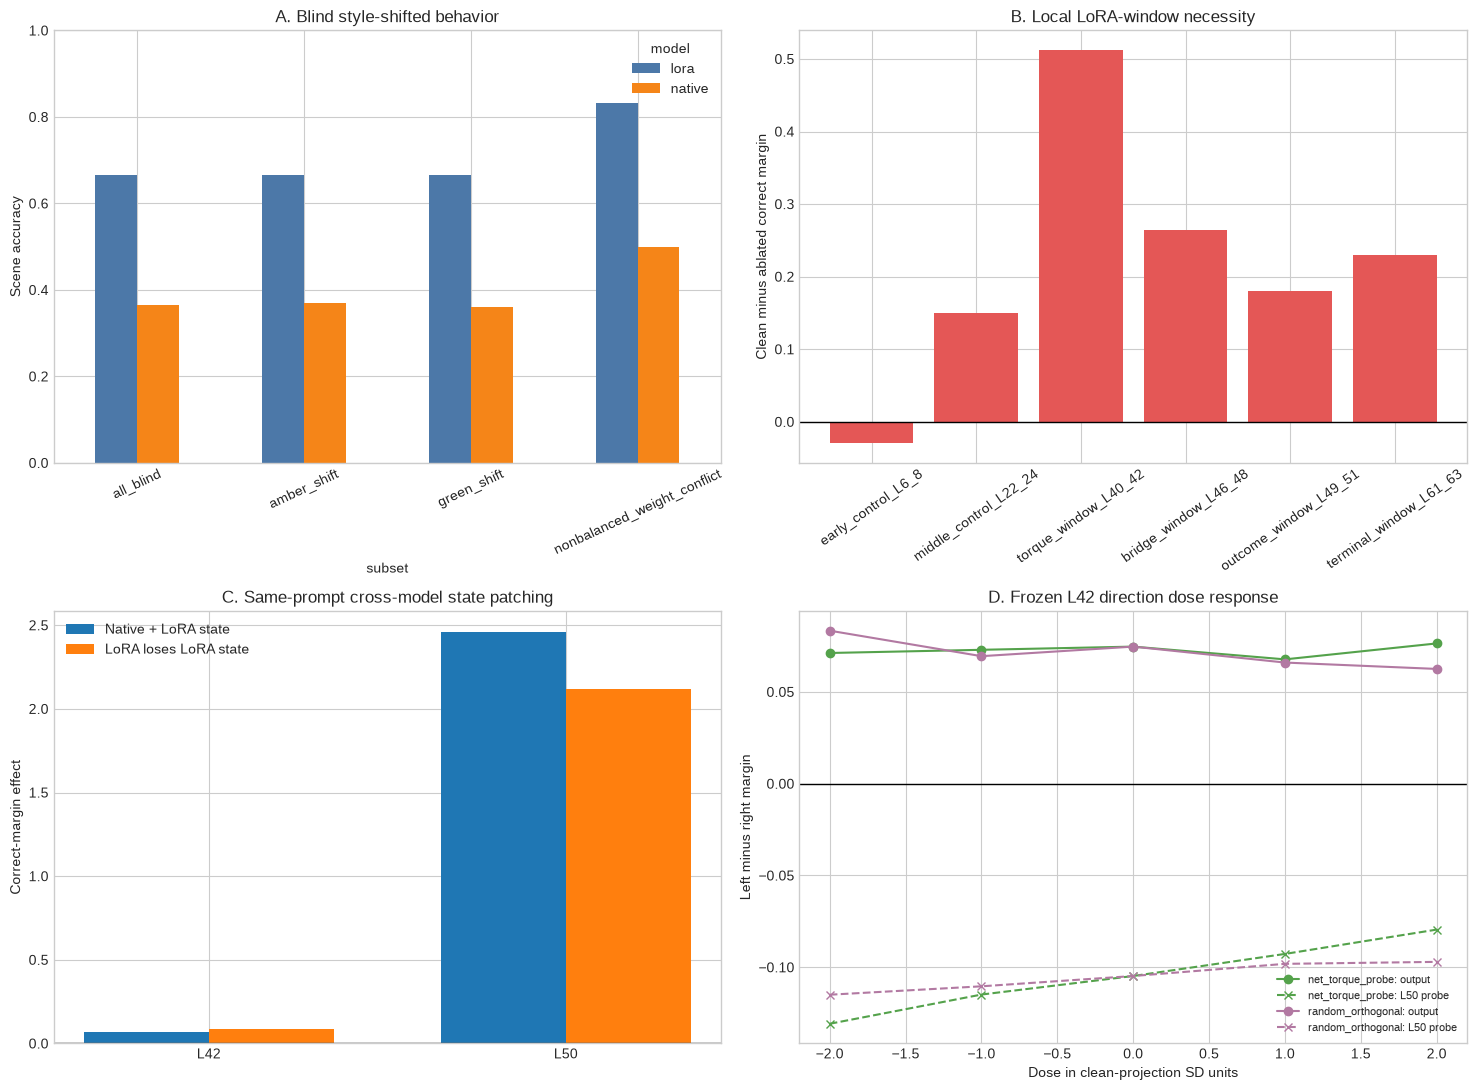

,window_name,layers,margin_n_scenes,margin_mean,margin_ci_low,margin_ci_high,margin_sign_flip_p,accuracy_drop,margin_bh_q
0,early_control_L6_8,"[6, 7, 8]",24,-0.0295,-0.0747,0.0122,0.2141,0.0000,0.2141
1,middle_control_L22_24,"[22, 23, 24]",24,0.1493,0.0747,0.2257,0.0013,0.0139,0.0016
2,torque_window_L40_42,"[40, 41, 42]",24,0.5122,0.4236,0.6024,0.0001,0.0278,0.0001
3,bridge_window_L46_48,"[46, 47, 48]",24,0.2639,0.1910,0.3264,0.0001,0.0000,0.0001
4,outcome_window_L49_51,"[49, 50, 51]",24,0.1806,0.1267,0.2240,0.0001,0.0000,0.0001
5,terminal_window_L61_63,"[61, 62, 63]",24,0.2292,0.1597,0.2865,0.0001,0.0000,0.0001


,layer_index,sufficiency_accuracy_change,sufficiency_n_scenes,sufficiency_mean,sufficiency_ci_low,sufficiency_ci_high,sufficiency_sign_flip_p,necessity_accuracy_drop,necessity_n_scenes,necessity_mean,necessity_ci_low,necessity_ci_high,necessity_sign_flip_p
0,42,-0.0139,24,0.0694,-0.0191,0.1510,0.1292,0.0139,24,0.0833,0.0313,0.1372,0.0051
1,50,0.3611,24,2.4618,1.7917,3.0747,0.0001,0.1389,24,2.1181,1.4913,2.6962,0.0001


,n_scenes,mean,ci_low,ci_high,sign_flip_p
torque_output_slope,24.000000,0.000521,-0.003125,0.003993,0.796020
random_output_slope,24.000000,-0.004514,-0.007986,-0.001215,0.011599
torque_minus_random_output_slope,24.000000,0.005035,0.000347,0.009722,0.040296
torque_mediator_slope,24.000000,0.012473,0.011394,0.013586,0.000100
random_mediator_slope,24.000000,0.004802,0.003576,0.005932,0.000100
torque_minus_random_mediator_slope,24.000000,0.007672,0.006085,0.009332,0.000100
torque_output_mediator_slope_correlation,0.317929,0.317929,0.317929,0.317929,0.317929


Frozen gates: {'blind_behavior_improves': True, 'any_local_lora_window_necessary': True, 'L50_state_sufficient': True, 'L50_state_necessary': True, 'torque_direction_controls_output': False, 'torque_direction_reaches_L50_outcome_state': True}


In [19]:
%%cell_progress 18/19 Aggregate scene-level causal effects and render figures
cell_stage('Loading intervention records')

def load_record_directory(directory, excluded_names=('identity.json',)):
    rows = []
    for file_path in sorted(Path(directory).glob('*.json')):
        if file_path.name in excluded_names:
            continue
        payload = json.loads(file_path.read_text(encoding='utf-8'))
        rows.extend(payload['records'])
    return pd.DataFrame(rows)

ablation_records = load_record_directory(ABLATION_DIR)
cross_records = load_record_directory(CROSS_PATCH_DIR)
direction_records = load_record_directory(
    DIRECTION_DIR,
    excluded_names=('identity.json', 'direction_manifest.json'),
)
assert ablation_records['example_id'].nunique() == len(causal_examples)
assert cross_records['example_id'].nunique() == len(causal_examples)
assert direction_records['example_id'].nunique() == len(causal_examples)

def scene_condition_mean(frame, condition_columns):
    numeric = [
        column for column in (
            'correct', 'correct_margin', 'left_right_margin',
            'mediator_left_right_margin', 'state_delta_norm',
        )
        if column in frame.columns
    ]
    group_columns = ['scene_id', 'outcome', 'weight_cue', 'style'] + condition_columns
    return (
        frame.assign(correct=frame['correct'].astype(float))
        .groupby(group_columns, dropna=False, as_index=False)[numeric]
        .mean()
    )

ablation_scene = scene_condition_mean(
    ablation_records, ['condition', 'window_name']
)
cross_scene = scene_condition_mean(
    cross_records, ['condition']
)
direction_scene = scene_condition_mean(
    direction_records, ['axis_name', 'dose_units']
)
ablation_scene.to_csv(
    ANALYSIS_DIR / 'ablation_scene_metrics.csv', index=False
)
cross_scene.to_csv(
    ANALYSIS_DIR / 'cross_patch_scene_metrics.csv', index=False
)
direction_scene.to_csv(
    ANALYSIS_DIR / 'direction_scene_metrics.csv', index=False
)

def bootstrap_summary(values, seed):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    assert len(values)
    rng = np.random.default_rng(seed)
    draws = np.empty(BOOTSTRAP_REPLICATES, dtype=float)
    for index in range(BOOTSTRAP_REPLICATES):
        sample = values[rng.integers(0, len(values), size=len(values))]
        draws[index] = sample.mean()
    low, high = np.quantile(draws, [0.025, 0.975])
    signs = rng.choice(
        (-1.0, 1.0), size=(SIGN_FLIP_REPLICATES, len(values))
    )
    null = np.mean(signs * values[None, :], axis=1)
    p_value = float(
        (np.sum(np.abs(null) >= abs(values.mean())) + 1)
        / (SIGN_FLIP_REPLICATES + 1)
    )
    return {
        'n_scenes': int(len(values)),
        'mean': float(values.mean()),
        'ci_low': float(low),
        'ci_high': float(high),
        'sign_flip_p': p_value,
    }

def bh_adjust(p_values):
    values = np.asarray(p_values, dtype=float)
    order = np.argsort(values)
    adjusted = np.empty_like(values)
    running = 1.0
    for rank_index in range(len(values) - 1, -1, -1):
        original_index = order[rank_index]
        rank = rank_index + 1
        running = min(running, values[original_index] * len(values) / rank)
        adjusted[original_index] = running
    return np.minimum(adjusted, 1.0)

cell_stage('Testing localized LoRA necessity')
clean_ablation = ablation_scene[
    ablation_scene['condition'] == 'lora_clean'
][['scene_id', 'correct', 'correct_margin']].rename(columns={
    'correct': 'clean_correct',
    'correct_margin': 'clean_correct_margin',
})
ablation_rows = []
for window_name in ABLATION_WINDOWS:
    current = ablation_scene[
        ablation_scene['window_name'] == window_name
    ].merge(clean_ablation, on='scene_id', validate='one_to_one')
    margin_effect = (
        current['clean_correct_margin'] - current['correct_margin']
    )
    accuracy_effect = current['clean_correct'] - current['correct']
    row = {
        'window_name': window_name,
        'layers': list(ABLATION_WINDOWS[window_name]),
        **{
            f'margin_{key}': value
            for key, value in bootstrap_summary(
                margin_effect,
                BLIND_SEED + 100 + len(ablation_rows),
            ).items()
        },
        'accuracy_drop': float(accuracy_effect.mean()),
    }
    ablation_rows.append(row)
ablation_effects = pd.DataFrame(ablation_rows)
ablation_effects['margin_bh_q'] = bh_adjust(
    ablation_effects['margin_sign_flip_p']
)
ablation_effects.to_csv(
    ANALYSIS_DIR / 'ablation_effects.csv', index=False
)

cell_stage('Testing cross-model state sufficiency and necessity')
clean_native = cross_scene[
    cross_scene['condition'] == 'native_clean'
][['scene_id', 'correct', 'correct_margin']].rename(columns={
    'correct': 'native_correct',
    'correct_margin': 'native_margin',
})
clean_lora = cross_scene[
    cross_scene['condition'] == 'lora_clean'
][['scene_id', 'correct', 'correct_margin']].rename(columns={
    'correct': 'lora_correct',
    'correct_margin': 'lora_margin',
})
cross_rows = []
for layer_index in PATCH_LAYERS:
    suff = cross_scene[
        cross_scene['condition']
        == f'native_recipient_lora_state_L{layer_index}'
    ].merge(clean_native, on='scene_id', validate='one_to_one')
    nec = cross_scene[
        cross_scene['condition']
        == f'lora_recipient_native_state_L{layer_index}'
    ].merge(clean_lora, on='scene_id', validate='one_to_one')
    suff_effect = suff['correct_margin'] - suff['native_margin']
    nec_effect = nec['lora_margin'] - nec['correct_margin']
    cross_rows.append({
        'layer_index': layer_index,
        'sufficiency_accuracy_change': float(
            (suff['correct'] - suff['native_correct']).mean()
        ),
        **{
            f'sufficiency_{key}': value
            for key, value in bootstrap_summary(
                suff_effect, BLIND_SEED + 200 + layer_index
            ).items()
        },
        'necessity_accuracy_drop': float(
            (nec['lora_correct'] - nec['correct']).mean()
        ),
        **{
            f'necessity_{key}': value
            for key, value in bootstrap_summary(
                nec_effect, BLIND_SEED + 300 + layer_index
            ).items()
        },
    })
cross_effects = pd.DataFrame(cross_rows)
cross_effects.to_csv(
    ANALYSIS_DIR / 'cross_patch_effects.csv', index=False
)

cell_stage('Testing torque-axis dose response and mediator transport')
direction_slope_rows = []
for (scene_id, axis_name), group in direction_scene.groupby(
    ['scene_id', 'axis_name'], sort=True
):
    group = group.sort_values('dose_units')
    output_slope = float(np.polyfit(
        group['dose_units'], group['left_right_margin'], 1
    )[0])
    mediator_slope = float(np.polyfit(
        group['dose_units'],
        group['mediator_left_right_margin'],
        1,
    )[0])
    direction_slope_rows.append({
        'scene_id': scene_id,
        'axis_name': axis_name,
        'output_left_right_slope': output_slope,
        'mediator_left_right_slope': mediator_slope,
    })
direction_slopes = pd.DataFrame(direction_slope_rows)
pivot_output = direction_slopes.pivot(
    index='scene_id', columns='axis_name',
    values='output_left_right_slope',
)
pivot_mediator = direction_slopes.pivot(
    index='scene_id', columns='axis_name',
    values='mediator_left_right_slope',
)
direction_effects = {
    'torque_output_slope': bootstrap_summary(
        pivot_output['net_torque_probe'], BLIND_SEED + 401
    ),
    'random_output_slope': bootstrap_summary(
        pivot_output['random_orthogonal'], BLIND_SEED + 402
    ),
    'torque_minus_random_output_slope': bootstrap_summary(
        pivot_output['net_torque_probe']
        - pivot_output['random_orthogonal'],
        BLIND_SEED + 403,
    ),
    'torque_mediator_slope': bootstrap_summary(
        pivot_mediator['net_torque_probe'], BLIND_SEED + 404
    ),
    'random_mediator_slope': bootstrap_summary(
        pivot_mediator['random_orthogonal'], BLIND_SEED + 405
    ),
    'torque_minus_random_mediator_slope': bootstrap_summary(
        pivot_mediator['net_torque_probe']
        - pivot_mediator['random_orthogonal'],
        BLIND_SEED + 406,
    ),
    'torque_output_mediator_slope_correlation': float(np.corrcoef(
        pivot_output['net_torque_probe'],
        pivot_mediator['net_torque_probe'],
    )[0, 1]),
}
direction_slopes.to_csv(
    ANALYSIS_DIR / 'direction_scene_slopes.csv', index=False
)
write_json_atomic(
    ANALYSIS_DIR / 'direction_effects.json', direction_effects
)

cell_stage('Rendering confirmatory figures')
plt.style.use('seaborn-v0_8-whitegrid')
figure, axes = plt.subplots(2, 2, figsize=(15, 11))

behavior_plot = behavior_summary[
    behavior_summary['subset'].isin([
        'all_blind', 'nonbalanced_weight_conflict',
        'amber_shift', 'green_shift',
    ])
].pivot(index='subset', columns='model', values='accuracy')
behavior_plot.plot(kind='bar', ax=axes[0, 0], color=['#4C78A8', '#F58518'])
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_ylabel('Scene accuracy')
axes[0, 0].set_title('A. Blind style-shifted behavior')
axes[0, 0].tick_params(axis='x', rotation=25)

axes[0, 1].bar(
    ablation_effects['window_name'],
    ablation_effects['margin_mean'],
    color='#E45756',
)
axes[0, 1].axhline(0, color='black', linewidth=1)
axes[0, 1].set_ylabel('Clean minus ablated correct margin')
axes[0, 1].set_title('B. Local LoRA-window necessity')
axes[0, 1].tick_params(axis='x', rotation=35)

x = np.arange(len(PATCH_LAYERS))
width = 0.35
axes[1, 0].bar(
    x - width / 2, cross_effects['sufficiency_mean'],
    width, label='Native + LoRA state',
)
axes[1, 0].bar(
    x + width / 2, cross_effects['necessity_mean'],
    width, label='LoRA loses LoRA state',
)
axes[1, 0].axhline(0, color='black', linewidth=1)
axes[1, 0].set_xticks(x, [f'L{value}' for value in PATCH_LAYERS])
axes[1, 0].set_ylabel('Correct-margin effect')
axes[1, 0].set_title('C. Same-prompt cross-model state patching')
axes[1, 0].legend()

for axis_name, color in (
    ('net_torque_probe', '#54A24B'),
    ('random_orthogonal', '#B279A2'),
):
    current = direction_scene[
        direction_scene['axis_name'] == axis_name
    ].groupby('dose_units', as_index=False).agg(
        output=('left_right_margin', 'mean'),
        mediator=('mediator_left_right_margin', 'mean'),
    )
    axes[1, 1].plot(
        current['dose_units'], current['output'],
        marker='o', color=color, label=f'{axis_name}: output',
    )
    axes[1, 1].plot(
        current['dose_units'], current['mediator'],
        marker='x', linestyle='--', color=color,
        label=f'{axis_name}: L50 probe',
    )
axes[1, 1].axhline(0, color='black', linewidth=1)
axes[1, 1].set_xlabel('Dose in clean-projection SD units')
axes[1, 1].set_ylabel('Left minus right margin')
axes[1, 1].set_title('D. Frozen L42 direction dose response')
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / 'blind_causal_validation_summary.png',
    dpi=180, bbox_inches='tight',
)
plt.show()

causal_decision = {
    'schema_version': 'qwen27b-postlora-blind-causal-decision-1.0',
    'behavior': {
        'paired_accuracy_effect': behavior_effect,
        'exact_mcnemar_p': mcnemar_p,
    },
    'ablation': ablation_effects.to_dict(orient='records'),
    'cross_model_patch': cross_effects.to_dict(orient='records'),
    'direction': direction_effects,
    'gates': {
        'blind_behavior_improves': behavior_effect['ci_low'] > 0,
        'any_local_lora_window_necessary': bool((
            (ablation_effects['margin_mean'] > 0)
            & (ablation_effects['margin_bh_q'] < ALPHA_LEVEL)
        ).any()),
        'L50_state_sufficient': bool(
            cross_effects.loc[
                cross_effects['layer_index'] == OUTCOME_LAYER,
                'sufficiency_ci_low',
            ].iloc[0] > 0
        ),
        'L50_state_necessary': bool(
            cross_effects.loc[
                cross_effects['layer_index'] == OUTCOME_LAYER,
                'necessity_ci_low',
            ].iloc[0] > 0
        ),
        'torque_direction_controls_output': (
            direction_effects['torque_output_slope']['ci_low'] > 0
            and direction_effects[
                'torque_minus_random_output_slope'
            ]['ci_low'] > 0
        ),
        'torque_direction_reaches_L50_outcome_state': (
            direction_effects['torque_mediator_slope']['ci_low'] > 0
            and direction_effects[
                'torque_minus_random_mediator_slope'
            ]['ci_low'] > 0
        ),
    },
    'interpretation_limit': (
        'Passing gates support a frozen torque-to-outcome routing hypothesis '
        'under final-token hybrid interventions. They do not identify a unique '
        'circuit or prove explicit multiplication.'
    ),
}
write_json_atomic(
    ANALYSIS_DIR / 'causal_decision.json', causal_decision
)

display(ablation_effects.round(4))
display(cross_effects.round(4))
display(pd.DataFrame(direction_effects).T)
print('Frozen gates:', causal_decision['gates'])


In [20]:
%%cell_progress 19/19 Verify the blind confirmatory package
cell_stage('Checking immutable inputs and required outputs')
required_outputs = (
    PROTOCOL_LOCK_PATH,
    BLIND_DATASET_LOCK_PATH,
    BLIND_DATASET_DIR / 'image_hashes.json',
    OUTPUT_ROOT / 'blind_scene_manifest.jsonl',
    OUTPUT_ROOT / 'causal_example_manifest.jsonl',
    ANALYSIS_DIR / 'blind_behavior_scene_comparison.csv',
    ANALYSIS_DIR / 'blind_behavior_summary.csv',
    ANALYSIS_DIR / 'blind_behavior_paired_effect.json',
    CLEAN_STATE_DIR / 'identity.json',
    CLEAN_STATE_DIR / 'index.jsonl',
    CLEAN_STATE_DIR / 'self_patch_parity.json',
    DIRECTION_DIR / 'direction_manifest.json',
    DIRECTION_DIR / 'frozen_directions.pt',
    ANALYSIS_DIR / 'ablation_scene_metrics.csv',
    ANALYSIS_DIR / 'ablation_effects.csv',
    ANALYSIS_DIR / 'cross_patch_scene_metrics.csv',
    ANALYSIS_DIR / 'cross_patch_effects.csv',
    ANALYSIS_DIR / 'direction_scene_metrics.csv',
    ANALYSIS_DIR / 'direction_scene_slopes.csv',
    ANALYSIS_DIR / 'direction_effects.json',
    ANALYSIS_DIR / 'causal_decision.json',
    FIGURE_DIR / 'blind_causal_validation_summary.png',
)
missing = [str(path) for path in required_outputs if not Path(path).is_file()]
assert not missing, 'Missing required outputs:\n' + '\n'.join(missing)

assert len(read_jsonl(OUTPUT_ROOT / 'blind_scene_manifest.jsonl')) == 216
assert len(read_jsonl(OUTPUT_ROOT / 'causal_example_manifest.jsonl')) == 72
assert sha256_file(ADAPTER_MANIFEST_PATH) == protocol_identity[
    'adapter_manifest_sha256'
]
assert sha256_file(FROZEN_HYPOTHESES_PATH) == protocol_identity[
    'frozen_hypotheses_sha256'
]

completion = {
    'schema_version': 'qwen27b-postlora-blind-causal-validation-complete-1.0',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_dir': str(ADAPTER_DIR),
    'blind_scenes': 216,
    'causal_scenes': 24,
    'source_or_mirror_geometry_overlap': 0,
    'frozen_torque_layer': TORQUE_LAYER,
    'frozen_outcome_layer': OUTCOME_LAYER,
    'decision_path': str(ANALYSIS_DIR / 'causal_decision.json'),
    'figure_path': str(
        FIGURE_DIR / 'blind_causal_validation_summary.png'
    ),
    'required_outputs': [str(path) for path in required_outputs],
}
write_json_atomic(OUTPUT_ROOT / 'RUN_COMPLETE.json', completion)
print('Blind causal validation complete:', OUTPUT_ROOT / 'RUN_COMPLETE.json')
print('Primary decision:', ANALYSIS_DIR / 'causal_decision.json')
print('Summary figure:', FIGURE_DIR / 'blind_causal_validation_summary.png')


Verify the blind confirmatory package:  95%|#########4| 18/19 [00:00<?, ?cell/s]

Blind causal validation complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_blind_causal_validation_v1/RUN_COMPLETE.json
Primary decision: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_blind_causal_validation_v1/analysis/causal_decision.json
Summary figure: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_blind_causal_validation_v1/analysis/figures/blind_causal_validation_summary.png
